In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../../ecommerce_dataset_updated.csv")
df = df.rename(columns={"Price (Rs.)": "Price",
                        "Discount (%)": "Discount",
                        "Final_Price(Rs.)": "Final_Price"})
df["Purchase_Date"] = pd.to_datetime(df["Purchase_Date"], dayfirst=True)
sns.set_theme(style="whitegrid")

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

## box plot


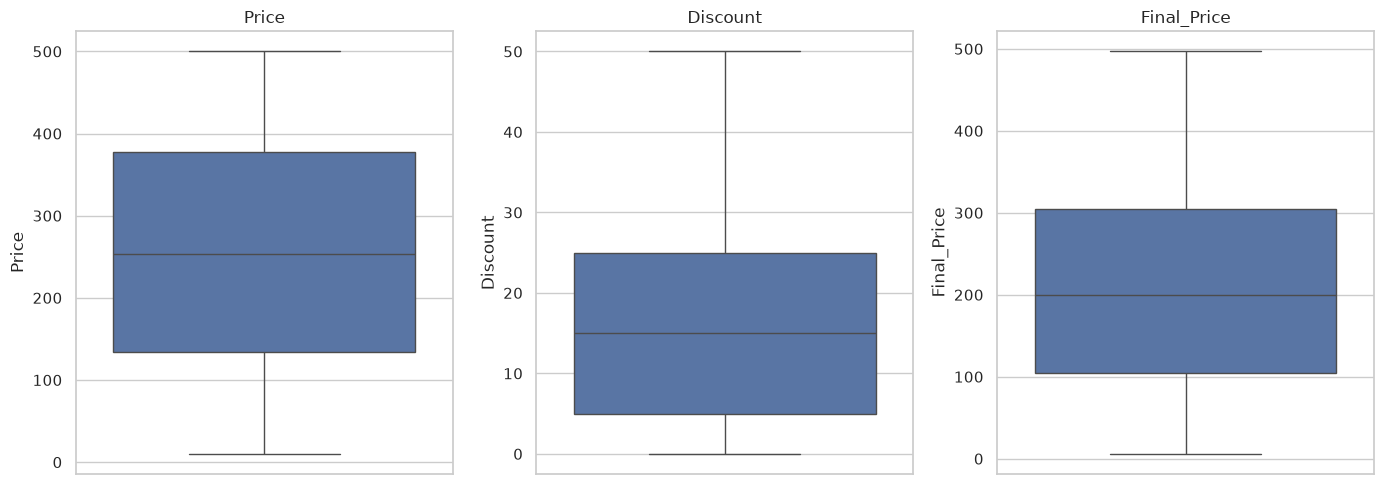

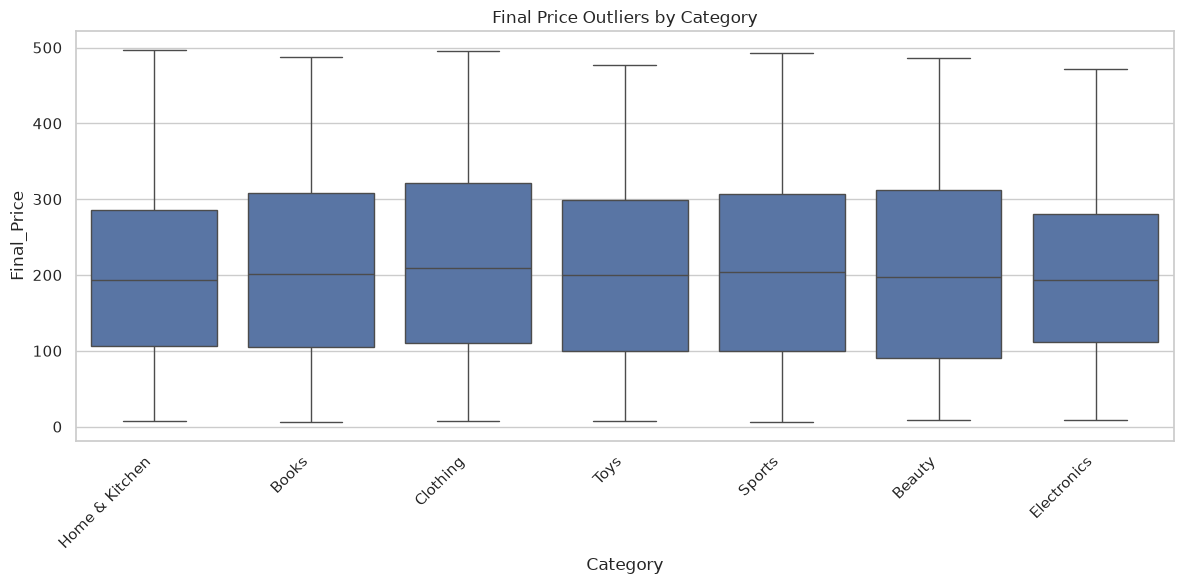

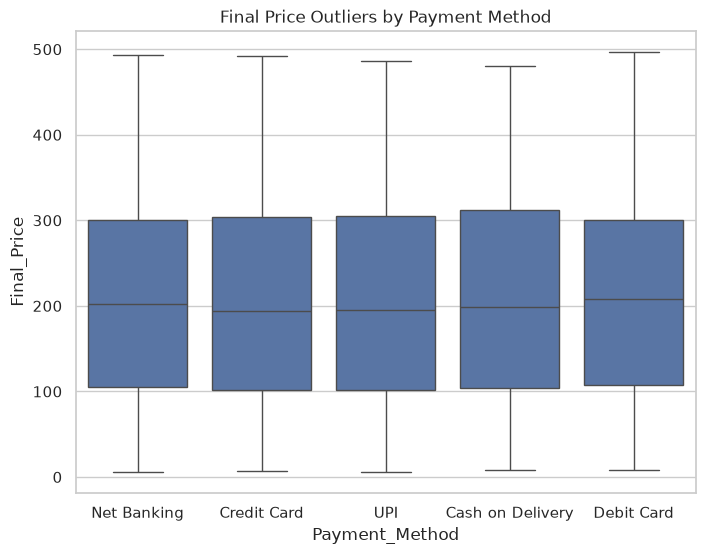

Price: 0 outliers
Discount: 0 outliers
Final_Price: 0 outliers


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, col in zip(axes, ["Price", "Discount", "Final_Price"]):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

# By group
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="Category", y="Final_Price",
            order=df["Category"].value_counts().index)
plt.xticks(rotation=45, ha="right"); plt.title("Final Price Outliers by Category")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x="Payment_Method", y="Final_Price")
plt.title("Final Price Outliers by Payment Method"); plt.show()

# Count them
for col in ["Price", "Discount", "Final_Price"]:
    print(f"{col}: {iqr_outliers(df[col]).sum()} outliers")

## scatter plot

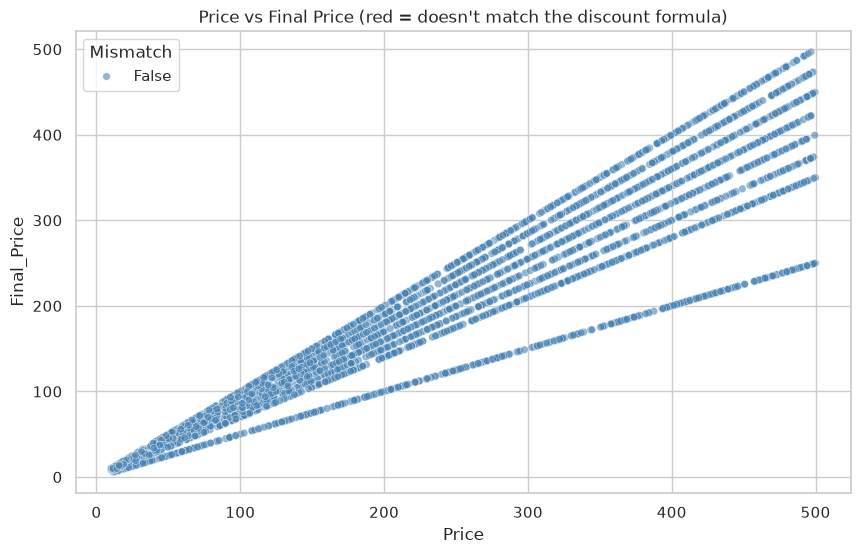

Rows breaking the formula: 0
Empty DataFrame
Columns: [User_ID, Product_ID, Category, Price, Discount, Final_Price, Payment_Method, Purchase_Date, Expected, Mismatch]
Index: []


In [5]:
df["Expected"] = df["Price"] * (1 - df["Discount"] / 100)
df["Mismatch"] = (df["Final_Price"] - df["Expected"]).abs() > 1   # tolerance of Rs.1

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Price", y="Final_Price", hue="Mismatch",
                palette={False: "steelblue", True: "crimson"}, alpha=0.6, s=30)
plt.title("Price vs Final Price (red = doesn't match the discount formula)")
plt.show()

print("Rows breaking the formula:", df["Mismatch"].sum())
print(df[df["Mismatch"]].head())

## time series

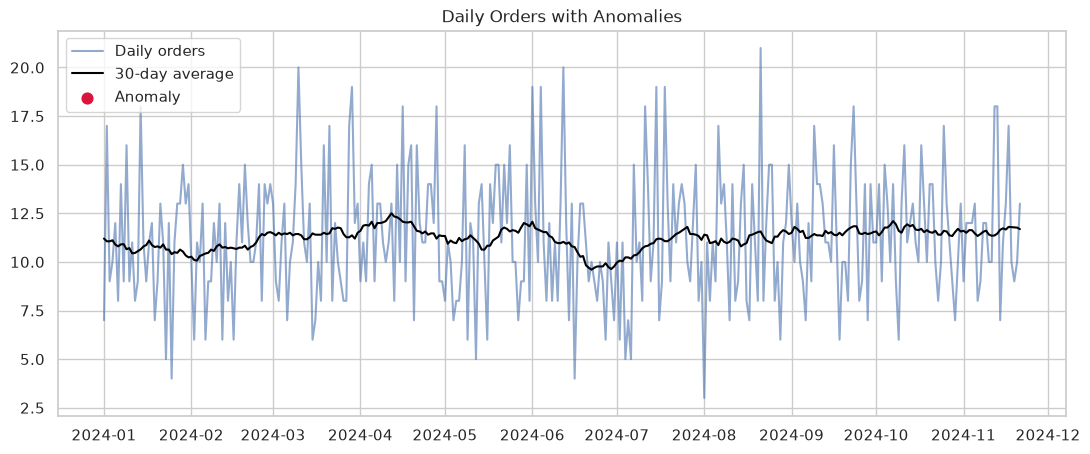

Anomalous days:
 Series([], Freq: D, dtype: int64)


In [6]:
daily = df.set_index("Purchase_Date").resample("D").size()

roll_mean = daily.rolling(30, center=True, min_periods=7).mean()
roll_std  = daily.rolling(30, center=True, min_periods=7).std()
z = (daily - roll_mean) / roll_std
anomalies = daily[z.abs() > 3]

plt.figure(figsize=(13, 5))
plt.plot(daily, alpha=0.6, label="Daily orders")
plt.plot(roll_mean, color="black", label="30-day average")
plt.scatter(anomalies.index, anomalies.values, color="crimson", s=60, zorder=3, label="Anomaly")
plt.title("Daily Orders with Anomalies"); plt.legend(); plt.show()

print("Anomalous days:\n", anomalies)